In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import optax
from tqdm import trange

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)


n_r = 2.333
n_b = 0.9
n_g = 2.0626
n_y = 1.562

# OSN input (must match the condition used for theta_opt / Hessian cells below)
x = jnp.array([0.5, 0.5])

# Functions with different n values

In [2]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [3]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    n_g_val = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass n_g_val as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g_val)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [5]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_117_in_0.5_yonly_0.2_in_1.0_all_0.5_ng.pkl'

with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (117, 13)
Number of samples: 117
Number of parameters per sample: 13


# Stability check

In [6]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g_val)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [10]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 117 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 117 samples for analysis



--- Stability at in_1.0_out_0.5 ---


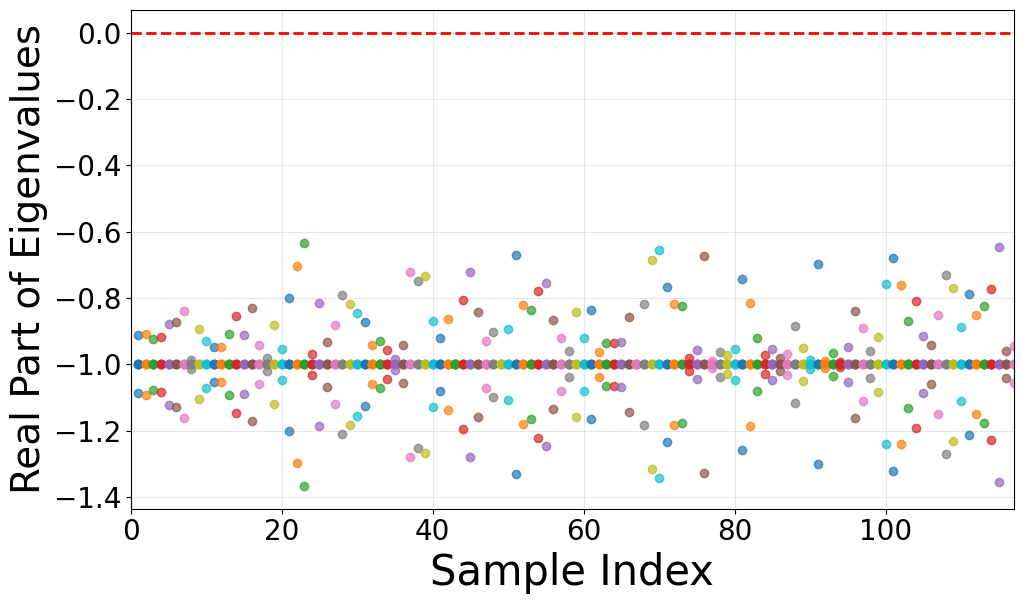


STABILITY SUMMARY

Stable samples: 117/117 (100.0%)


In [11]:
# Analyze stability 
# Operating point: in=1.0, out=0.5

stability_results_all = {}

# Choose operating points to test
ops = {
    "in_1.0_out_0.5": jnp.ones(m) * 1.0,
}


for op_name, x_op in ops.items():
    print(f"\n--- Stability at {op_name} ---")

    stability_results = []
    max_real_parts = []
    min_real_parts = []
    all_eigenvalues = []

    for i in range(n_samples_to_analyze):
        theta_star = theta_subset[i, :]

        try:
            # Fixed point outputs at this operating point
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x_op, m, n_r, n_b, n_y)

            # Construct state vector s* = [r, g, y]
            s_star = jnp.concatenate([r_star, g_star, y_star])

            # Verify it's a fixed point
            s_prime = F(s_star, theta_star, x_op, m, n_r, n_b, n_y)
            s_error = jnp.linalg.norm(s_prime - s_star)
            if s_error > 1e-3:
                print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

            # Compute stability (n_g is taken from theta[12] via unpack_theta)
            result = compute_stability(F, s_star, theta_star, x_op, m, tau=1.0, n_r=n_r, n_b=n_b, n_y=n_y)
            stability_results.append(result)

            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            all_eigenvalues.append(result['eigenvalues'])

        except Exception as e:
            print(f"  Sample {i+1}: Error - {e}")
            continue

    stability_results_all[op_name] = {
        "stability_results": stability_results,
        "max_real_parts": max_real_parts,
        "min_real_parts": min_real_parts,
        "all_eigenvalues": all_eigenvalues,
    }

    # visualise stability results
    fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    actual_no_samples = len(stability_results)
    for i in range(actual_no_samples):
        real_parts = stability_results[i]['real_parts']
        ax1.plot([i + 1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i + 1}' if i < 5 else '')

    ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
    ax1.set_xlabel('Sample Index', fontsize=30)
    ax1.set_ylabel('Real Part of Eigenvalues', fontsize=28)
    ax1.set_xlim(0, max(actual_no_samples, 1))
    ax1.grid(True, alpha=0.3)

    stable_count = sum(1 for r in stability_results if r['is_stable'])

    plt.tight_layout()
    plt.tick_params(axis='both', direction='out')
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    # plt.savefig(f'Figures/stability_{op_name}.eps')
    plt.show()

    # print summary
    print("\n" + "=" * 70)
    print("STABILITY SUMMARY")
    print("=" * 70)
    if actual_no_samples > 0:
        print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100 * stable_count / actual_no_samples:.1f}%)")
    else:
        print("\nNo valid samples to summarise.")


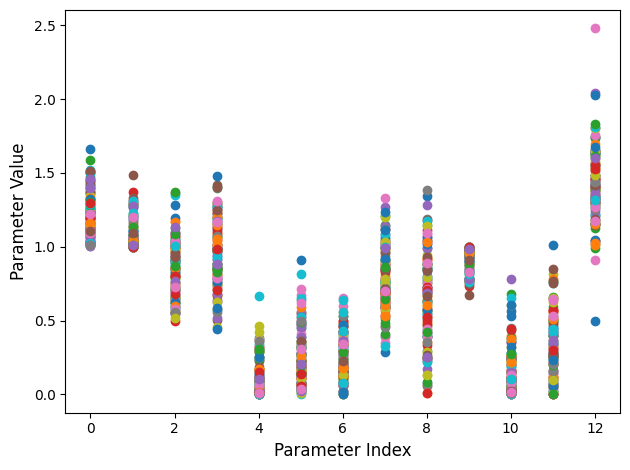

In [12]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


# Compute Hessian

In [ ]:
theta_opt[0]

array([1.5085497 , 1.189102  , 1.2838918 , 0.88042754, 0.3805814 ,
       0.38809043, 0.15685856, 0.6876284 , 0.2286601 , 0.8409705 ,
       0.1567103 , 0.01159689, 1.4589677 ], dtype=float32)

In [14]:
_th = theta_opt[0].copy()
print(mitral_output(_th, x, m, n_r, n_b, n_y))
_th[12] = 1.8
print(mitral_output(_th, x, m, n_r, n_b, n_y))


(Array([0.14378692, 0.14378692], dtype=float32), Array([0.23029009, 0.23029009], dtype=float32), Array([0.34891027, 0.34891027], dtype=float32), Array([0.2, 0.2], dtype=float32))
(Array([0.14821409, 0.14821409], dtype=float32), Array([0.18473798, 0.18473798], dtype=float32), Array([0.34891027, 0.34891027], dtype=float32), Array([0.20216815, 0.20216815], dtype=float32))


Processing 117 samples...
  Sample 1/117...
  Sample 101/117...
Completed processing 117 samples


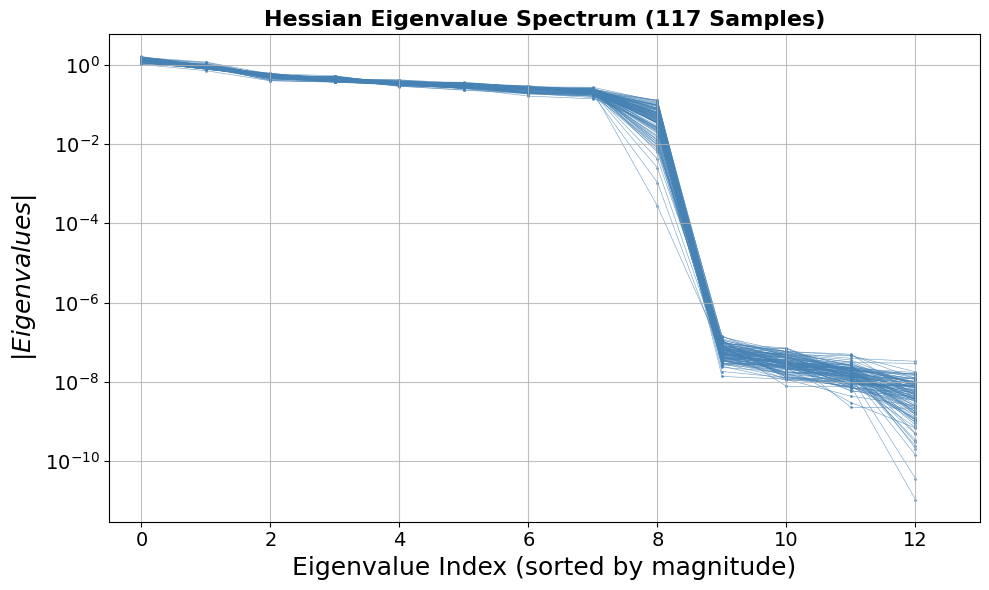

In [15]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
all_eigenvectors.shape

13

In [22]:
v = jnp.zeros(n_params)
v = v.at[12].set(1)
v@v.T
v[:, None] * v[None, :]

Array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]],      dtype=float32)

/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_79147/329781723.py:12: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-8) @ H2 @ v #pseudo inverse


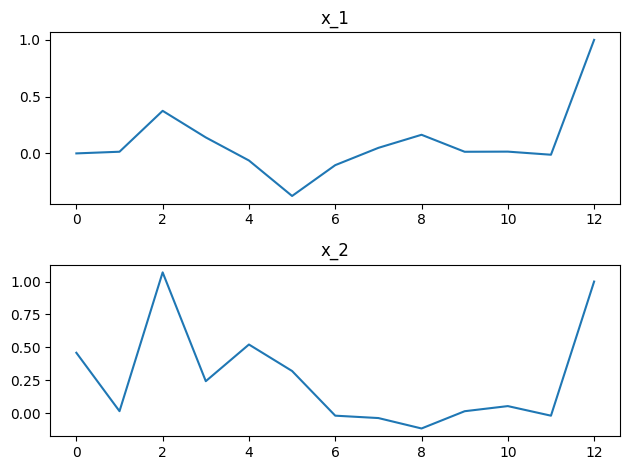

In [56]:

x_c = 0.1
v = jnp.zeros(n_params)
v = v.at[12].set(1)

# let H1 = ((I-vv^T)^T)H(I-vv^T)
H1 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H @ (jnp.eye(n_params) - v[:, None] * v[None, :])

# let H2 = (I-vv^T)H
H2 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H

#x_free = - H1 inverse * H2 * v
x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-8) @ H2 @ v #pseudo inverse

####################
eps = 1e-8
H1_reg = H1 + eps * jnp.eye(H1.shape[0])
x_free_2 = - np.linalg.solve(H1_reg, H2 @ v)

fig, axs = plt.subplots(2, 1)  # 2 rows, 1 column
axs[0].plot(x_free_1+v)
axs[0].set_title("x_1")
axs[1].plot(x_free_2+v)
axs[1].set_title("x_2")

plt.tight_layout()
plt.show()




In [110]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]

v = jnp.zeros(n_params)
v = v.at[12].set(1)

x_collect = []
for i in range(n_samples):
#for i in range(3):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    H1 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H @ (jnp.eye(n_params) - v[:, None] * v[None, :])
    H2 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H

    x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-8) @ H2 @ v #pseudo inverse
    x_collect.append(x_free_1 + v)

x_collect = jnp.array(x_collect)




  Sample 1/117...
  Sample 101/117...


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_79147/3973205365.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-8) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_79147/3973205365.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-8) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_79147/3973205365.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e

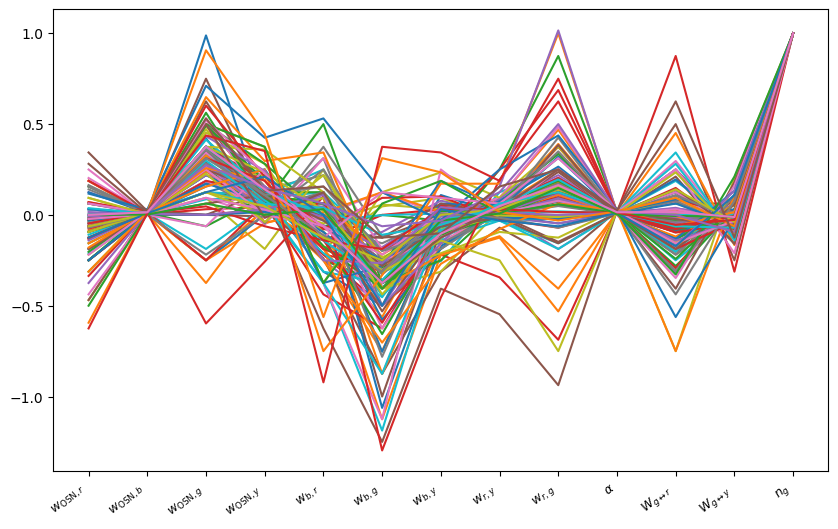

In [111]:

#plot each row of x_collect

PARAM_NAMES = [
    r"$w_{\mathrm{OSN},r}$",
    r"$w_{\mathrm{OSN},b}$",
    r"$w_{\mathrm{OSN},g}$",
    r"$w_{\mathrm{OSN},y}$",
    r"$w_{b,r}$",
    r"$w_{b,g}$",
    r"$w_{b,y}$",
    r"$w_{r,y}$",
    r"$w_{r,g}$",
    r"$\alpha$",
    r"$W_{g\leftrightarrow r}$",
    r"$W_{g\leftrightarrow y}$",
    r"$n_g$",
]

param_idx = np.arange(n_params)
fig, ax = plt.subplots(figsize=(10, 6))
for i in range(x_collect.shape[0]):
    ax.plot(x_collect[i, :])
    ax.set_xticks(param_idx)
    ax.set_xticklabels(PARAM_NAMES, rotation=40, ha="right", fontsize=9)
    #label the x axis with the parameter names per index
plt.show()



In [128]:
_, s, vt = jnp.linalg.svd(x_collect)

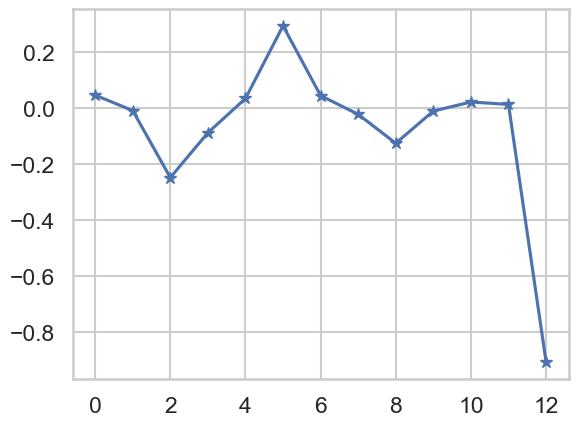

In [133]:
plt.plot(vt[0,:],"-*")
plt.show()

above is special mu star (gullaum photo 2 april)


In [98]:
x_collect[2:].shape

(115, 13)

In [ ]:
v = jnp.zeros(n_params)
v = v.at[12].set(1)

# Projector onto the "free" subspace (orthogonal to v)
P = jnp.eye(n_params) - v[:, None] * v[None, :]

# let H1 = P^T H P (P is symmetric)
H1 = P @ H @ P

# let H2 = P H
H2 = P @ H

b = H2 @ v

# Baseline: pseudoinverse solution in the free subspace
x_free_1 = - jnp.linalg.pinv(H1, rtol=1e-8) @ b

####################
# Proper regularization for this construction:
# - H1 is singular along v by design (because of P)
# - adding eps*I changes the constrained direction too
# So we ridge only on the free subspace via (ridge * P)
# and solve with lstsq for robustness.
eps = 1e-6
scale = (jnp.linalg.norm(H1, ord="fro") / jnp.sqrt(n_params)) + 1e-12
ridge = eps * scale
A = H1 + ridge * P

x_free_2 = - jnp.linalg.lstsq(A, b, rcond=None)[0]

# Ensure x is in the free subspace (numerical cleanup)
x_free_2 = P @ x_free_2

fig, axs = plt.subplots(2, 1)
axs[0].plot(x_free_1 + v)
axs[0].set_title("x_free_1")
axs[1].plot(x_free_2 + v)
axs[1].set_title("x_free_2 (ridge on free subspace)")

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

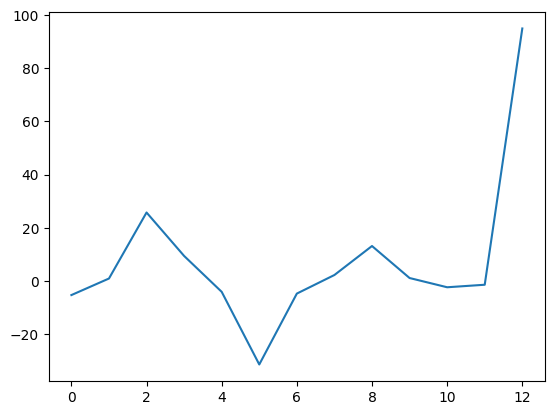

In [112]:
#normalise the rows of x_collect
x_collect = x_collect / jnp.linalg.norm(x_collect, axis=1, keepdims=True)

#sum across all rows of x_collect
x_collect.sum(axis=0)

plt.plot(x_collect.sum(axis=0))
plt.show()

In [114]:
x_collect[2,:].shape

(13,)

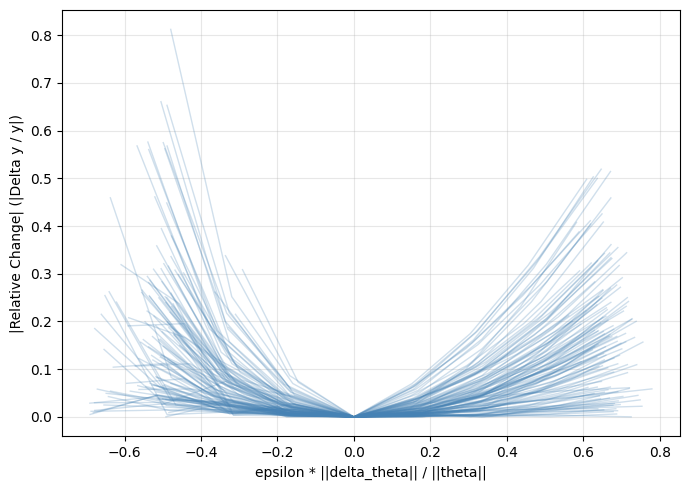

In [ ]:
import seaborn as sns

# epsilon grid
eps = np.arange(-2.0, 2.0 + 0.2, 0.5)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_y)

mitral_output_single = jax.jit(_mitral_single)
theta_opt_subset = jnp.array(theta_opt[:n_samples])

x_collect_np = np.array(x_collect)

# Use only the first row of x_collect as the direction
dtheta = x_collect_np[0, :]
dtheta_norm = float(np.linalg.norm(dtheta))
if dtheta_norm < 1e-12:
    raise ValueError("x_collect[0] has ~zero norm")

direction = jnp.array(dtheta / dtheta_norm)

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(7, 5))

x_axes = []
curves = []

# Step along this direction for DIFFERENT theta_opt values (one curve per theta)
for i_theta in range(int(theta_opt_subset.shape[0])):
    theta0 = theta_opt_subset[i_theta]
    theta0_norm = float(np.linalg.norm(np.array(theta0)))
    if theta0_norm < 1e-12:
        continue

    _, _, _, y0 = mitral_output_single(theta0)
    y0 = np.array(y0)
    y0_comp = float(y0[0])

    curve = []
    for e in eps:
        theta_step = theta0 + float(e) * direction
        _, _, _, y = mitral_output_single(theta_step)
        y = np.array(y)
        y_comp = float(y[0])

        rel = (y_comp - y0_comp) / y0_comp if abs(y0_comp) > 1e-12 else (y_comp - y0_comp)
        curve.append(abs(rel))

    x_axis = eps * (dtheta_norm / theta0_norm)

    x_axes.append(np.asarray(x_axis, dtype=float))
    curves.append(np.asarray(curve, dtype=float))

# Interpolate all curves onto a shared x-grid so we can average
if len(curves) == 0:
    raise ValueError("No valid theta0 samples produced curves")

x_mins = [xa.min() for xa in x_axes]
x_maxs = [xa.max() for xa in x_axes]
x_min = max(x_mins)
x_max = min(x_maxs)

if not np.isfinite(x_min) or not np.isfinite(x_max) or x_min >= x_max:
    # Fallback: use a shared scale based on median ||theta||
    theta_norms = [float(np.linalg.norm(np.array(theta_opt_subset[i]))) for i in range(int(theta_opt_subset.shape[0]))]
    theta_norms = [t for t in theta_norms if t > 1e-12 and np.isfinite(t)]
    theta0_norm_med = float(np.median(theta_norms)) if theta_norms else 1.0
    common_x = np.asarray(eps * (dtheta_norm / theta0_norm_med), dtype=float)
else:
    common_x = np.linspace(x_min, x_max, 200)

Y = []
for xa, ya in zip(x_axes, curves):
    # xa is monotonic because eps is monotonic and the scale is positive
    y_interp = np.interp(common_x, xa, ya)
    Y.append(y_interp)

Y = np.vstack(Y)
y_mean = Y.mean(axis=0)
y_std = Y.std(axis=0)

# Optional context: individual curves (very light)
for xa, ya in zip(x_axes, curves):
    ax.plot(xa, ya, color="0.6", alpha=0.15, linewidth=1)

ax.plot(common_x, y_mean, color="steelblue", linewidth=2.5, label="Mean")
ax.fill_between(common_x, y_mean - y_std, y_mean + y_std, color="steelblue", alpha=0.25, label="±1 std")

ax.set_xlabel('epsilon * ||delta_theta|| / ||theta||')
ax.set_ylabel('|Relative Change| (|Delta y / y|)')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


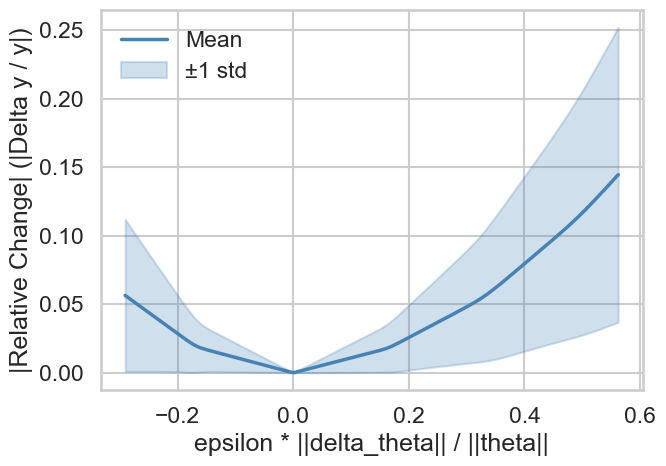

In [123]:
import seaborn as sns

# epsilon grid
eps = np.arange(-2.0, 2.0 + 0.2, 0.5)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_y)

mitral_output_single = jax.jit(_mitral_single)
theta_opt_subset = jnp.array(theta_opt[:n_samples])

x_collect_np = np.array(x_collect)

# Use only the first row of x_collect as the direction
dtheta = x_collect_np[0, :]
dtheta_norm = float(np.linalg.norm(dtheta))
if dtheta_norm < 1e-12:
    raise ValueError("x_collect[0] has ~zero norm")

direction = jnp.array(dtheta / dtheta_norm)

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(7, 5))

x_axes = []
curves = []

# Step along this direction for different theta_opt values (one curve per theta)
for i_theta in range(int(theta_opt_subset.shape[0])):
    theta0 = theta_opt_subset[i_theta]
    theta0_norm = float(np.linalg.norm(np.array(theta0)))
    if theta0_norm < 1e-12:
        continue

    _, _, _, y0 = mitral_output_single(theta0)
    y0 = np.array(y0)
    y0_comp = float(y0[0])

    curve = []
    for e in eps:
        theta_step = theta0 + float(e) * direction
        _, _, _, y = mitral_output_single(theta_step)
        y = np.array(y)
        y_comp = float(y[0])

        rel = (y_comp - y0_comp) / y0_comp if abs(y0_comp) > 1e-12 else (y_comp - y0_comp)
        curve.append(abs(rel))

    x_axis = eps * (dtheta_norm / theta0_norm)

    x_axes.append(np.asarray(x_axis, dtype=float))
    curves.append(np.asarray(curve, dtype=float))

x_mins = [xa.min() for xa in x_axes]
x_maxs = [xa.max() for xa in x_axes]
x_min = max(x_mins)
x_max = min(x_maxs)

Y = []
for xa, ya in zip(x_axes, curves):
    # xa is monotonic because eps is monotonic and the scale is positive
    y_interp = np.interp(common_x, xa, ya)
    Y.append(y_interp)

Y = np.vstack(Y)
y_mean = Y.mean(axis=0)
y_std = Y.std(axis=0)


ax.plot(common_x, y_mean, color="steelblue", linewidth=2.5, label="Mean")
ax.fill_between(common_x, y_mean - y_std, y_mean + y_std, color="steelblue", alpha=0.25, label="±1 std")

ax.set_xlabel('epsilon * ||delta_theta|| / ||theta||')
ax.set_ylabel('|Relative Change| (|Delta y / y|)')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


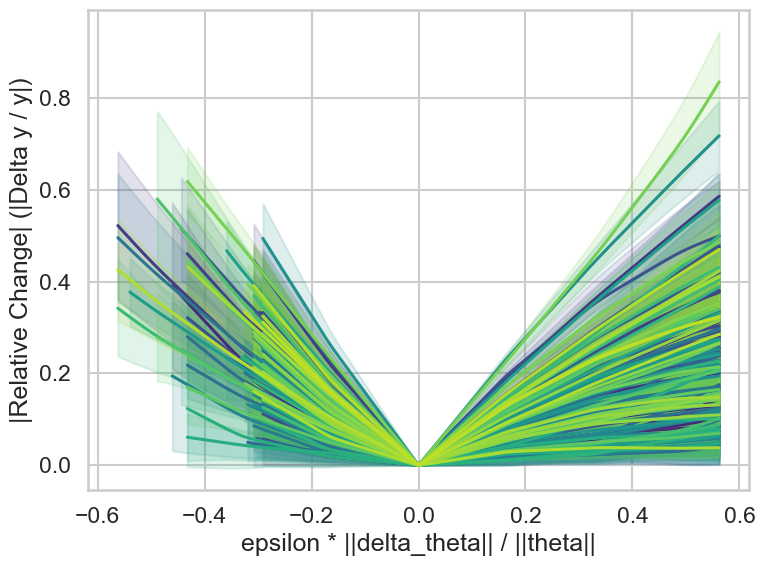

In [122]:
import seaborn as sns

# epsilon grid
eps = np.arange(-2.0, 2.0 + 0.2, 0.5)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_y)

mitral_output_single = jax.jit(_mitral_single)
theta_opt_subset = jnp.array(theta_opt[:n_samples])

x_collect_np = np.array(x_collect)

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.cm.viridis(np.linspace(0.1, 0.9, x_collect_np.shape[0]))

for row_idx in range(x_collect_np.shape[0]):
    dtheta = x_collect_np[row_idx, :]
    dtheta_norm = float(np.linalg.norm(dtheta))
    if dtheta_norm < 1e-12:
        raise ValueError(f"x_collect[{row_idx}] has ~zero norm")

    direction = jnp.array(dtheta / dtheta_norm)

    x_axes = []
    curves = []

    # Step along this direction for different theta_opt values (one curve per theta)
    for i_theta in range(int(theta_opt_subset.shape[0])):
        theta0 = theta_opt_subset[i_theta]
        theta0_norm = float(np.linalg.norm(np.array(theta0)))
        if theta0_norm < 1e-12:
            continue

        _, _, _, y0 = mitral_output_single(theta0)
        y0 = np.array(y0)
        y0_comp = float(y0[0])

        curve = []
        for e in eps:
            theta_step = theta0 + float(e) * direction
            _, _, _, y = mitral_output_single(theta_step)
            y = np.array(y)
            y_comp = float(y[0])

            rel = (y_comp - y0_comp) / y0_comp if abs(y0_comp) > 1e-12 else (y_comp - y0_comp)
            curve.append(abs(rel))

        x_axis = eps * (dtheta_norm / theta0_norm)

        x_axes.append(np.asarray(x_axis, dtype=float))
        curves.append(np.asarray(curve, dtype=float))

    if not x_axes:
        continue

    x_min = max(xa.min() for xa in x_axes)
    x_max = min(xa.max() for xa in x_axes)
    common_x = np.linspace(x_min, x_max, 200)

    Y = []
    for xa, ya in zip(x_axes, curves):
        y_interp = np.interp(common_x, xa, ya)
        Y.append(y_interp)

    Y = np.vstack(Y)
    y_mean = Y.mean(axis=0)
    y_std = Y.std(axis=0)

    color = colors[row_idx]
    ax.plot(common_x, y_mean, color=color, linewidth=2.2)
    ax.fill_between(common_x, y_mean - y_std, y_mean + y_std, color=color, alpha=0.15)

ax.set_xlabel('epsilon * ||delta_theta|| / ||theta||')
ax.set_ylabel('|Relative Change| (|Delta y / y|)')
plt.tight_layout()
plt.show()